In [1]:
load_ext jupyter_black

In [2]:
import os
import pandas as pd
from scipy.stats import chi2_contingency, false_discovery_control
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

/tmp/ipykernel_37840/921268189.py:3: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.0)
  from scipy.stats import chi2_contingency, false_discovery_control


In [3]:
demographics = {
    "prism": [
        "age",
        "gender",
        "employment_status",
        "education",
        "marital_status",
        "english_proficiency",
        "religion",
        "ethnicity",
        "birth_region",
        "reside_region",
        "lm_familiarity",
    ]
}

  0%|                                                                                        | 0/11 [00:00<?, ?it/s]

(23, 6)


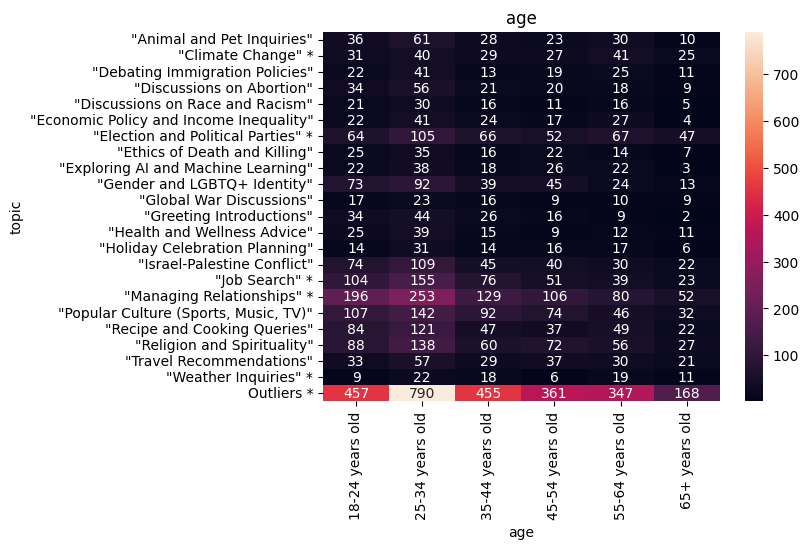

  9%|███████▎                                                                        | 1/11 [00:01<00:14,  1.45s/it]

(23, 4)


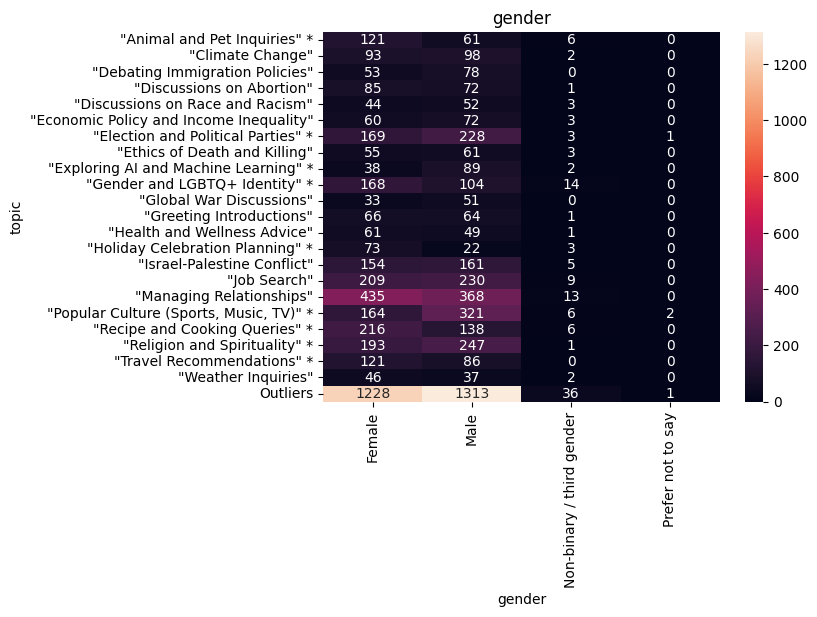

 18%|██████████████▌                                                                 | 2/11 [00:02<00:10,  1.19s/it]

(23, 8)


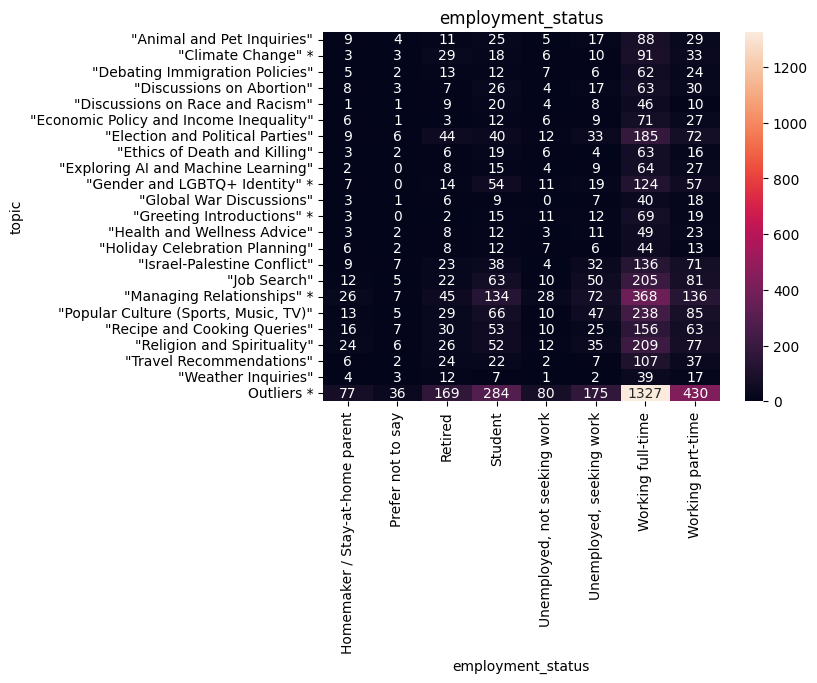

 27%|█████████████████████▊                                                          | 3/11 [00:03<00:09,  1.23s/it]

(23, 9)


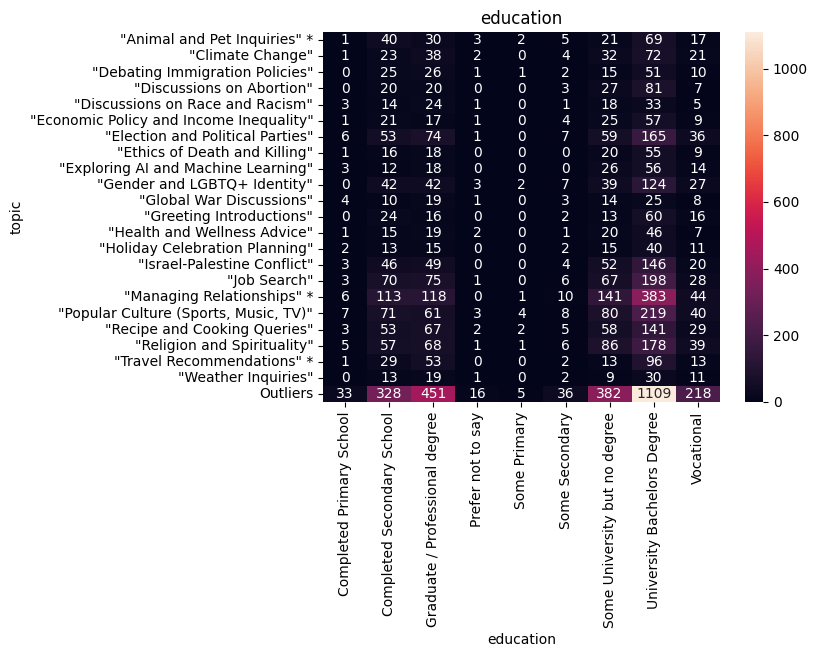

 36%|█████████████████████████████                                                   | 4/11 [00:05<00:09,  1.31s/it]

(23, 5)


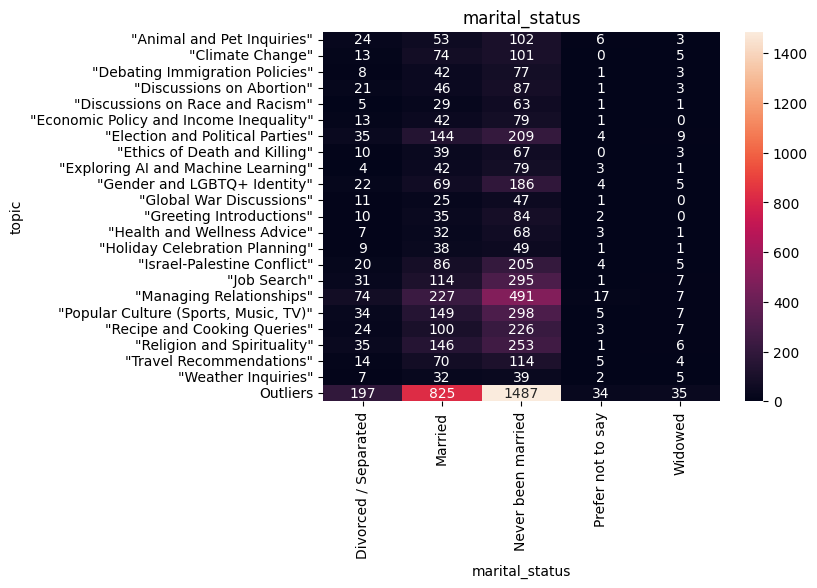

 45%|████████████████████████████████████▎                                           | 5/11 [00:05<00:06,  1.11s/it]

(23, 5)


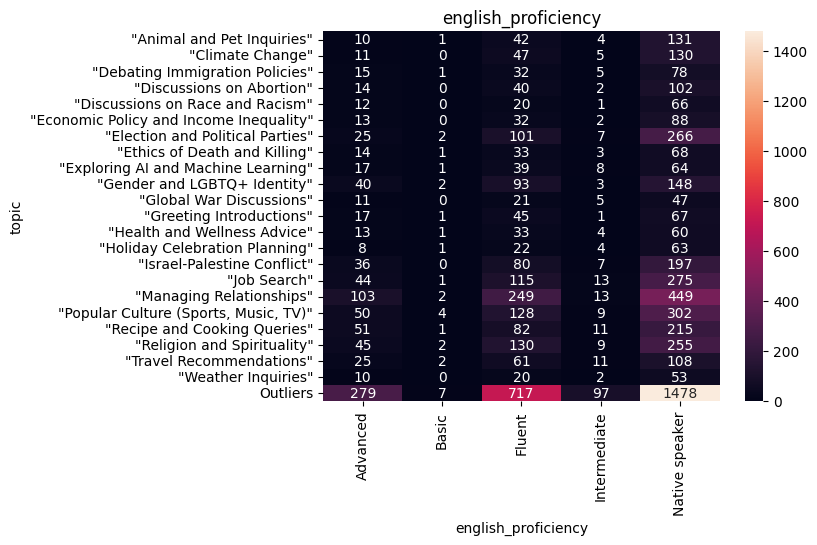

 55%|███████████████████████████████████████████▋                                    | 6/11 [00:06<00:04,  1.09it/s]

(23, 6)


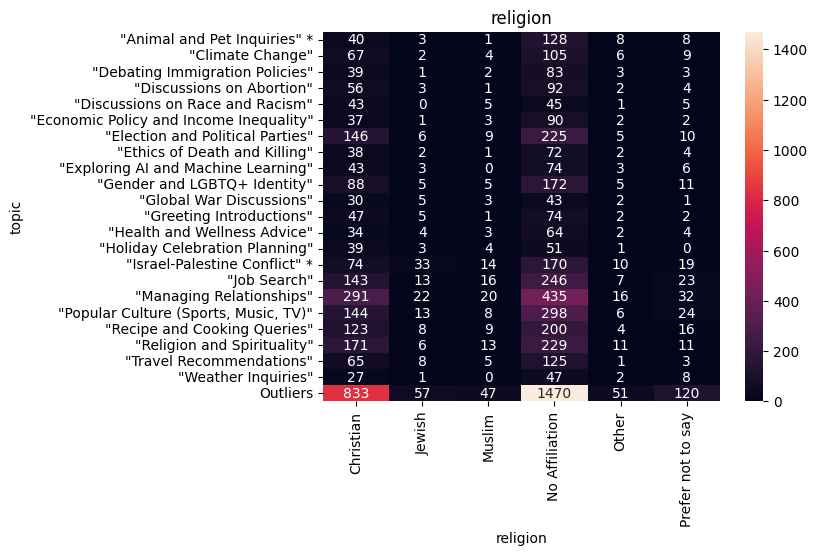

 64%|██████████████████████████████████████████████████▉                             | 7/11 [00:07<00:03,  1.26it/s]

(23, 7)


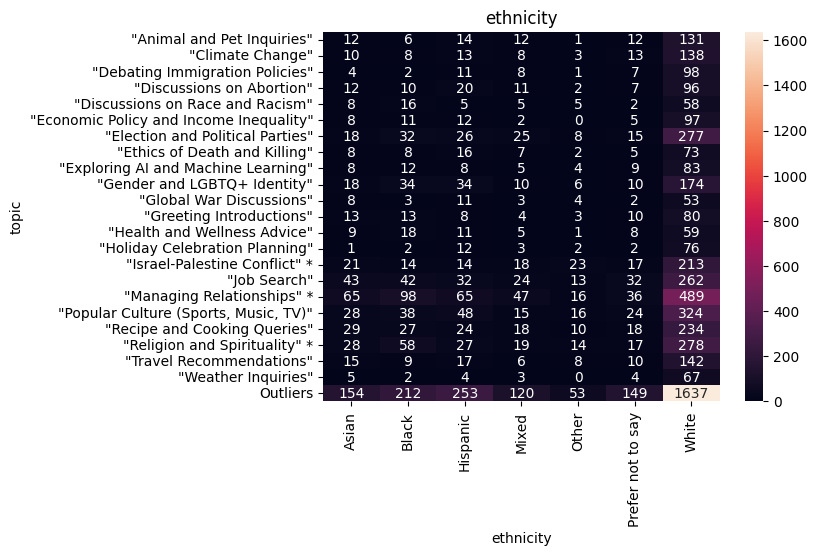

 73%|██████████████████████████████████████████████████████████▏                     | 8/11 [00:07<00:02,  1.30it/s]

(23, 6)


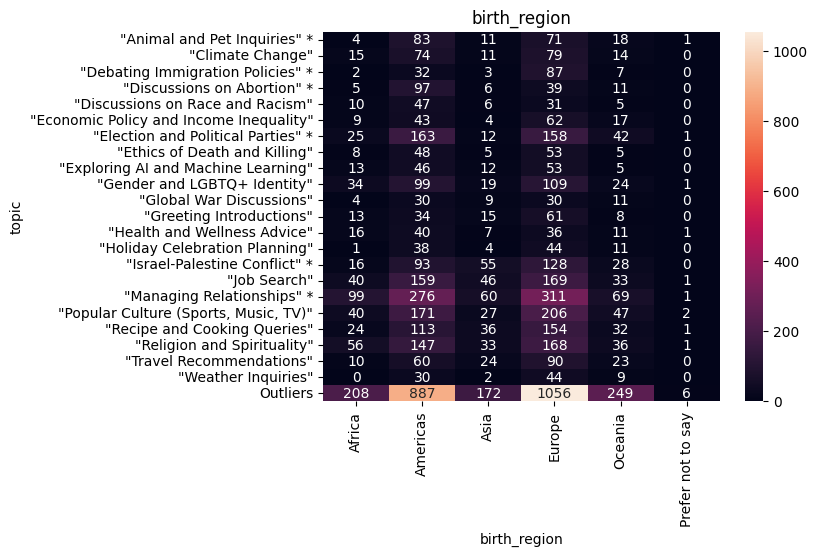

 82%|█████████████████████████████████████████████████████████████████▍              | 9/11 [00:08<00:01,  1.43it/s]

(23, 6)


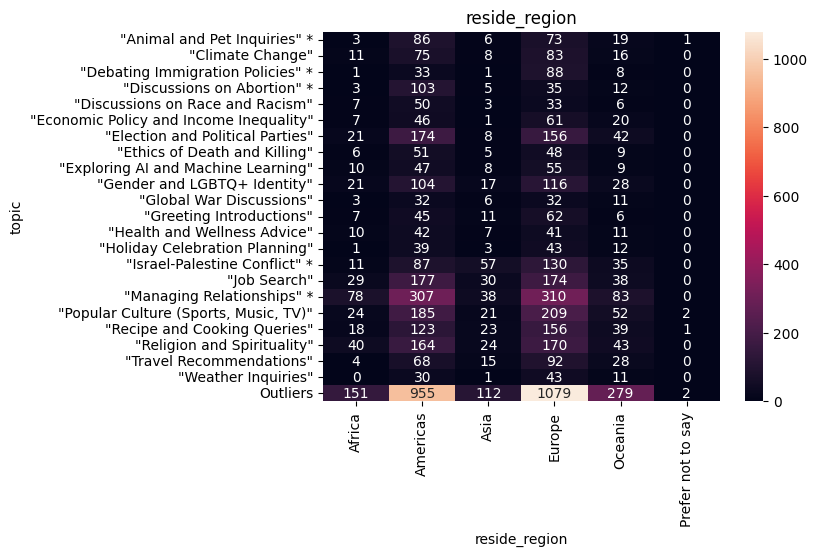

 91%|███████████████████████████████████████████████████████████████████████▊       | 10/11 [00:08<00:00,  1.54it/s]

(23, 3)


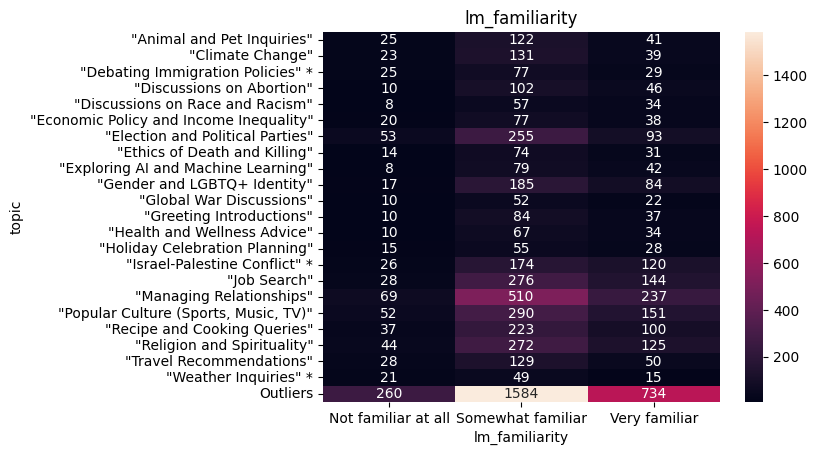

100%|███████████████████████████████████████████████████████████████████████████████| 11/11 [00:09<00:00,  1.19it/s]


In [4]:
for dataset in demographics:
    df = pd.read_pickle(f"data/{dataset + '_utterances'}_linguistic.gz").drop(
        columns=[
            "s_neutral_model_response",
            "s_neutral_user_prompt",
            "model_response_liwc_Segment",
            "user_prompt_liwc_Segment",
        ],
        errors="ignore",
    )
    for c in ["politeness_user_prompt", "politeness_model_response"]:
        if c in df:
            df[c] = df[c].replace(
                {"impolite": 0, "neutral": 0.5, "polite": 1, "somewhat polite": 0.75}
            )
    df = df.rename(columns={"gpt_description": "topic"})
    group_cols = ["conversation_id"] + demographics[dataset] + ["topic"]
    df = (
        df.groupby(group_cols)[
            [
                c
                for c in df.columns
                if ("model_response" in c or "user_prompt" in c)
                and (c not in ["model_response", "user_prompt"])
            ]
        ]
        .mean()
        .reset_index()
    )
    for demographic in tqdm(demographics[dataset]):
        plot_df = (
            df.groupby([demographic, "topic"], as_index=False)
            .count()
            .rename(columns={"conversation_id": "count"})
        )
        plot_df = (
            pd.pivot_table(plot_df, "count", "topic", demographic).fillna(0).astype(int)
        )
        fig = plt.figure()
        sns.heatmap(plot_df, annot=True, fmt="d")
        locs, labels = plt.yticks()
        new_labels = []
        print(plot_df.shape)
        pvalues = []
        for row in plot_df.iterrows():
            pvalue = chi2_contingency(
                np.vstack(
                    [
                        row[1].to_numpy(),
                        plot_df.sum(axis=0).to_numpy() - row[1].to_numpy(),
                    ]
                )
            ).pvalue
            pvalues.append(pvalue)
        pvalues = false_discovery_control(pvalues)
        for i, label in enumerate(labels):
            if pvalues[i] < 0.05:
                new_labels.append(label.get_text() + " *")
            else:
                new_labels.append(label)
        plt.yticks(locs, new_labels)

        plt.title(demographic)
        plt.savefig(
            f"figures_topic_demo_corr/chisquared_{dataset}_{demographic.replace(' ','')}.pdf",
            bbox_inches="tight",
        )
        plt.show()